# ACT Finetune — OpenArm Basket Task

用 lerobot 0.5.1 的 **ACT** policy 訓練 basket pick-and-place。

**為什麼從 PI0.5 換 ACT？**  
PI0.5 finetune（30k step）replay 通過但 live inference 失敗：long-horizon compounding error 導致左臂 joint7 漂到 -1.57（嚴重 OOD）。  
ACT 內建 **temporal ensembling**（exponential weighted averaging across overlapping action chunks），是過去的關鍵理由——不是「模型較簡單」。

**重用：**
- Dataset：同一份 `datasets_lerobot/openarm/basket_task_v2`（456 ep，30 fps，16D folding 順序，左臂單獨任務）
- Stats patch：已從 PI0.5 階段套用，右臂 8 維 std=5e-3；ACT 用 MEAN_STD（denom=std+1e-8）→ 不需要再 patch

**新設定：**
- `temporal_ensemble_coeff=0.01` → 強制 `n_action_steps=1`，每幀 query 模型
- `chunk_size=60`（2 秒 horizon @ 30 fps，對齊 ACT 原版 Aloha 50Hz×100=2s）
- ACT 不吃 language → task 欄位不送進模型

執行環境：`conda activate lerobot`

流程：
1. 設定路徑
2. 驗證 dataset（不重建——v2 已被 PI0.5 用過，且 stats 已 patched）
3. 設定 ACT 參數
4. 訓練
5. 訓練曲線

## Block 1 — 環境確認

In [1]:
import sys
import torch
import lerobot

print(f"Python   : {sys.version.split()[0]}")
print(f"PyTorch  : {torch.__version__}")
print(f"CUDA     : {torch.version.cuda}")
print(f"GPU      : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"VRAM     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB" if torch.cuda.is_available() else "")
print(f"lerobot  : {lerobot.__version__}")

Python   : 3.12.13
PyTorch  : 2.7.1+cu126
CUDA     : 12.6
GPU      : NVIDIA GeForce RTX 3090
VRAM     : 25.3 GB
lerobot  : 0.5.1


## Block 2 — 路徑設定

Output dir 與 PI0.5 分開，免得互相覆蓋。

In [2]:
from pathlib import Path

# ── Dataset：重用 PI0.5 v2（folding 16D + 30 fps）──────────────────────────
LEROBOT_DATASET_ROOT = Path("/home/teddyminelab/openarm_isaaclab/datasets_lerobot")
DATASET_REPO_ID      = "openarm/basket_task_v2"

# ── ACT 訓練輸出 ─────────────────────────────────────────────────────────
TRAIN_OUTPUT_DIR = Path("/home/teddyminelab/openarm_isaaclab/outputs/finetune_act_basket")

# ── 訓練超參 ─────────────────────────────────────────────────────────────
BATCH_SIZE  = 8        # RTX 3090 24GB；ACT ~80M 比 PI0.5 小很多
TRAIN_STEPS = 100_000  # ACT 標準訓練量；3-4 小時範圍內
SAVE_FREQ   = 10_000
LOG_FREQ    = 200
LR          = 1e-5     # ACT 預設
LR_BACKBONE = 1e-5     # ACT 預設

# 只是給 dataset 看，ACT 模型本身不吃 language
TASK_LANGUAGE = "Pick up the cube and place it into the basket."

# 16D action/state names（與 PI0.5 v2 一致——folding 順序：R1..R7, R_grip, L1..L7, L_grip）
FOLDING_16D_NAMES = [
    "right_joint_1.pos", "right_joint_2.pos", "right_joint_3.pos", "right_joint_4.pos",
    "right_joint_5.pos", "right_joint_6.pos", "right_joint_7.pos", "right_gripper.pos",
    "left_joint_1.pos",  "left_joint_2.pos",  "left_joint_3.pos",  "left_joint_4.pos",
    "left_joint_5.pos",  "left_joint_6.pos",  "left_joint_7.pos",  "left_gripper.pos",
]

print("路徑設定完成（ACT recipe）：")
print(f"  Dataset    : {LEROBOT_DATASET_ROOT / DATASET_REPO_ID}")
print(f"  Output     : {TRAIN_OUTPUT_DIR}")
print(f"  Batch size : {BATCH_SIZE}")
print(f"  Steps      : {TRAIN_STEPS:,}")

路徑設定完成（ACT recipe）：
  Dataset    : /home/teddyminelab/openarm_isaaclab/datasets_lerobot/openarm/basket_task_v2
  Output     : /home/teddyminelab/openarm_isaaclab/outputs/finetune_act_basket
  Batch size : 8
  Steps      : 100,000


## Block 3 — 驗證資料集

**不重建 dataset**——v2 已從 PI0.5 階段建好，且 stats.json 已被 `/tmp/patch_basket_v2_stats.py` 修過（右臂 8 維 std=5e-3）。重建會覆蓋 patch。

In [3]:
import json
from lerobot.datasets.lerobot_dataset import LeRobotDataset

dataset_path = LEROBOT_DATASET_ROOT / DATASET_REPO_ID
if not dataset_path.exists():
    raise RuntimeError(f"Dataset not found at {dataset_path}. 請先跑 finetune_pi05_basket.ipynb Block 3 建出 v2 + Block 後 patch stats。")

dataset = LeRobotDataset(
    repo_id=DATASET_REPO_ID,
    root=dataset_path,
    video_backend="pyav",
)

print(f"Episodes : {dataset.num_episodes}")
print(f"Frames   : {dataset.num_frames}")
print(f"FPS      : {dataset.fps}")

sample = dataset[0]
print(f"action shape : {sample['action'].shape}")
print(f"state shape  : {sample['observation.state'].shape}")

# Sanity check：確認 stats patch 還在（右臂 8 維 std 不應該是 0）
stats = json.load(open(dataset_path / "meta" / "stats.json"))
right_arm_std = stats["observation.state"]["std"][:8]
min_std = min(abs(s) for s in right_arm_std)
print(f"\n右臂 std min = {min_std:.2e}")
if min_std < 1e-3:
    raise RuntimeError(
        f"Stats patch 沒上！右臂某維 std={min_std:.2e}。 \n"
        "→ 跑 `python3 /tmp/patch_basket_v2_stats.py` 後再進 Block 4。"
    )
print("✓ Stats 已 patched，可進入訓練設定")

/home/teddyminelab/miniconda3/envs/lerobot/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Episodes : 456
Frames   : 254145
FPS      : 30
action shape : torch.Size([16])
state shape  : torch.Size([16])

右臂 std min = 5.00e-03
✓ Stats 已 patched，可進入訓練設定


/home/teddyminelab/miniconda3/envs/lerobot/lib/python3.12/site-packages/torchvision/io/_video_deprecation_warning.py:5: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.warn(


## Block 4 — 設定 ACT 參數

**關鍵設定：**
- `chunk_size=60`：2 秒 horizon @ 30 fps（對齊 ACT 原版 2 秒）
- `temporal_ensemble_coeff=0.01`：開啟時序集成（ACT paper 預設值；強制 `n_action_steps=1`）
- `vision_backbone='resnet18'` + ImageNet 預訓練：ACT 預設
- 不需要 ACTION/STATE rename：dataset features 已經是標準 lerobot 命名

In [4]:
from lerobot.configs.train import TrainPipelineConfig
from lerobot.configs.default import DatasetConfig, WandBConfig
from lerobot.policies.act.configuration_act import ACTConfig
from lerobot.configs.types import FeatureType, NormalizationMode, PolicyFeature

policy_cfg = ACTConfig(
    device="cuda",                    # 對齊官方 notebook 的 --policy.device=cuda（不設會 fallback 到 cuda 但會印 warning）
    input_features={
        "observation.state": PolicyFeature(type=FeatureType.STATE, shape=(16,)),
        "observation.images.main":        PolicyFeature(type=FeatureType.VISUAL, shape=(3, 240, 320)),
        "observation.images.wrist_left":  PolicyFeature(type=FeatureType.VISUAL, shape=(3, 240, 320)),
        "observation.images.wrist_right": PolicyFeature(type=FeatureType.VISUAL, shape=(3, 240, 320)),
    },
    output_features={
        "action": PolicyFeature(type=FeatureType.ACTION, shape=(16,)),
    },
    # ── 時序設定（跟官方 default 不同的地方，全集中在這）──────────────────
    chunk_size=60,                  # 官方 default 100（Aloha 50Hz×2s）；30fps 改 60 = 2s 對齊
    n_action_steps=1,               # 官方 default 100；temporal ensembling 強制必須 =1
    temporal_ensemble_coeff=0.01,   # 官方 default None（不開）；ACT 論文預設 0.01——這是切過來的整個重點
    # ── Optimizer（與 ACT default 一致）────────────────────────────────
    optimizer_lr=LR,
    optimizer_lr_backbone=LR_BACKBONE,
    optimizer_weight_decay=1e-4,
    # ── Vision（與 ACT default 一致）──────────────────────────────────
    vision_backbone="resnet18",
    pretrained_backbone_weights="ResNet18_Weights.IMAGENET1K_V1",
    # ── Architecture（全部 ACT default，列出來方便日後調）───────────────
    dim_model=512,
    n_heads=8,
    dim_feedforward=3200,
    n_encoder_layers=4,
    n_decoder_layers=1,             # ACT 原始實作 bug——第一層之外都被忽略，這裡 match upstream
    use_vae=True,
    latent_dim=32,
    n_vae_encoder_layers=4,
    kl_weight=10.0,
    dropout=0.1,
    push_to_hub=False,
)

dataset_cfg = DatasetConfig(
    repo_id=DATASET_REPO_ID,
    root=str(LEROBOT_DATASET_ROOT / DATASET_REPO_ID),
    video_backend="pyav",
)

train_cfg = TrainPipelineConfig(
    dataset=dataset_cfg,
    policy=policy_cfg,
    output_dir=TRAIN_OUTPUT_DIR,
    batch_size=BATCH_SIZE,
    steps=TRAIN_STEPS,
    save_freq=SAVE_FREQ,
    log_freq=LOG_FREQ,
    num_workers=4,                  # ACT 訓練 IO 比 PI0.5 重（每 step 取整個 chunk）
    seed=42,
    wandb=WandBConfig(enable=False),
)

print("訓練設定（ACT，跟官方 default 不同處標 ★）：")
print(f"  Steps                    : {TRAIN_STEPS:,}")
print(f"  Batch size               : {BATCH_SIZE}")
print(f"  LR (head/backbone)       : {LR} / {LR_BACKBONE}")
print(f"  chunk_size             ★ : {policy_cfg.chunk_size}  (官方 100, 我們 60 = 2s @ 30fps)")
print(f"  n_action_steps         ★ : {policy_cfg.n_action_steps}  (官方 100, 我們 1 = temporal ensembling)")
print(f"  temporal_ensemble_coeff★ : {policy_cfg.temporal_ensemble_coeff}  (官方 None, 我們 0.01)")
print(f"  Output                   : {TRAIN_OUTPUT_DIR}")


訓練設定（ACT，跟官方 default 不同處標 ★）：
  Steps                    : 100,000
  Batch size               : 8
  LR (head/backbone)       : 1e-05 / 1e-05
  chunk_size             ★ : 60  (官方 100, 我們 60 = 2s @ 30fps)
  n_action_steps         ★ : 1  (官方 100, 我們 1 = temporal ensembling)
  temporal_ensemble_coeff★ : 0.01  (官方 None, 我們 0.01)
  Output                   : /home/teddyminelab/openarm_isaaclab/outputs/finetune_act_basket


## Block 4.5 — VRAM 狀態確認

若 Allocated > 1GB → 重啟 Kernel 從頭跑。

In [5]:
import torch, subprocess

if torch.cuda.is_available():
    alloc = torch.cuda.memory_allocated() / 1e9
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"Allocated : {alloc:.2f} GB / {total:.1f} GB total")
    print("✓ OK" if alloc < 1.0 else f"✗ {alloc:.1f}GB 殘留 → 重啟 Kernel")

result = subprocess.run(
    ["nvidia-smi", "--query-compute-apps=pid,used_memory,name",
     "--format=csv,noheader,nounits"],
    capture_output=True, text=True
)
if result.stdout.strip():
    print("\nnvidia-smi processes:")
    for line in result.stdout.strip().split("\n"):
        pid, mem, name = [x.strip() for x in line.split(",")]
        print(f"  PID {pid} | {mem} MiB | {name}")
else:
    print("\n（無 GPU process 佔用）")

Allocated : 0.00 GB / 25.3 GB total
✓ OK

（無 GPU process 佔用）


## Block 5 — 開始訓練

預估時間：100k steps @ batch=8、3 cameras → RTX 3090 約 **3-4 小時**。  
若 it/s 偏低（< 6），可早停（loss 應在 30-50k step 已大致收斂）；存活的 checkpoint 在 `outputs/finetune_act_basket/checkpoints/`。

ACT 比 PI0.5 小很多（~80M），不需要 meta device hack——直接用 lerobot 預設 `train()` 流程。

In [6]:
import logging
import shutil
import torch
from lerobot.scripts.lerobot_train import train

if torch.cuda.is_available():
    used = torch.cuda.memory_allocated() / 1e9
    if used > 1.0:
        raise RuntimeError(f"VRAM 有 {used:.1f}GB 殘留。請重啟 Kernel 再執行此 Block。")

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%H:%M:%S",
)

if TRAIN_OUTPUT_DIR.exists():
    print(f"刪除舊的輸出目錄: {TRAIN_OUTPUT_DIR}")
    shutil.rmtree(TRAIN_OUTPUT_DIR)

train(train_cfg)

INFO 2026-05-04 16:56:02 ot_train.py:197 {'batch_size': 8,
 'checkpoint_path': None,
 'cudnn_deterministic': False,
 'dataset': {'episodes': None,
             'image_transforms': {'enable': False,
                                  'max_num_transforms': 3,
                                  'random_order': False,
                                  'tfs': {'affine': {'kwargs': {'degrees': [-5.0,
                                                                            5.0],
                                                                'translate': [0.05,
                                                                              0.05]},
                                                     'type': 'RandomAffine',
                                                     'weight': 1.0},
                                          'brightness': {'kwargs': {'brightness': [0.8,
                                                                                   1.2]},
                            

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/teddyminelab/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 108MB/s] 
INFO 2026-05-04 16:56:04 ot_train.py:306 Creating optimizer and scheduler
INFO 2026-05-04 16:56:04 ot_train.py:341 Output dir: /home/teddyminelab/openarm_isaaclab/outputs/finetune_act_basket
INFO 2026-05-04 16:56:04 ot_train.py:348 cfg.steps=100000 (100K)
INFO 2026-05-04 16:56:04 ot_train.py:349 dataset.num_frames=254145 (254K)
INFO 2026-05-04 16:56:04 ot_train.py:350 dataset.num_episodes=456
INFO 2026-05-04 16:56:04 ot_train.py:353 Effective batch size: 8 x 1 = 8
INFO 2026-05-04 16:56:04 ot_train.py:354 num_learnable_params=51597200 (52M)
INFO 2026-05-04 16:56:04 ot_train.py:355 num_total_params=51597200 (52M)
Training:   0%|          | 0/100000 [00:00<?, ?step/s]INFO 2026-05-04 16:56:04 ot_train.py:419 Start offline training on a fixed dataset, with effective batch size: 8
/home/teddyminelab/miniconda3/envs/lerobot/lib/python3.12/site-packages/torchvision/io/_video_deprecation_warning.py:5: UserWarning: The video decoding and encod

## Block 6 — 確認 Checkpoint

In [7]:
checkpoints = sorted(TRAIN_OUTPUT_DIR.rglob("model.safetensors"))
print(f"找到 {len(checkpoints)} 個 checkpoint：")
for ck in checkpoints:
    size_mb = ck.stat().st_size / 1e6
    print(f"  {ck.relative_to(TRAIN_OUTPUT_DIR)}  ({size_mb:.0f} MB)")

找到 10 個 checkpoint：
  checkpoints/010000/pretrained_model/model.safetensors  (207 MB)
  checkpoints/020000/pretrained_model/model.safetensors  (207 MB)
  checkpoints/030000/pretrained_model/model.safetensors  (207 MB)
  checkpoints/040000/pretrained_model/model.safetensors  (207 MB)
  checkpoints/050000/pretrained_model/model.safetensors  (207 MB)
  checkpoints/060000/pretrained_model/model.safetensors  (207 MB)
  checkpoints/070000/pretrained_model/model.safetensors  (207 MB)
  checkpoints/080000/pretrained_model/model.safetensors  (207 MB)
  checkpoints/090000/pretrained_model/model.safetensors  (207 MB)
  checkpoints/100000/pretrained_model/model.safetensors  (207 MB)


## Block 7 — 訓練曲線

從 Block 5 stdout 抽 `loss` / `grad_norm` / `lr`，存到 `outputs/finetune_act_basket/training_curves.png`。

**注意：** 跑前先 Ctrl+S 存 notebook（這個 cell 從 .ipynb 檔讀 stdout，未存的讀不到）。

ACT 加上 KL loss 跟 PI0.5 不同——log 中 `loss` 是 `l1_loss + kl_weight * kld_loss`。

解析到 500 個記錄點，step 200 ~ 99,999 / 100,000


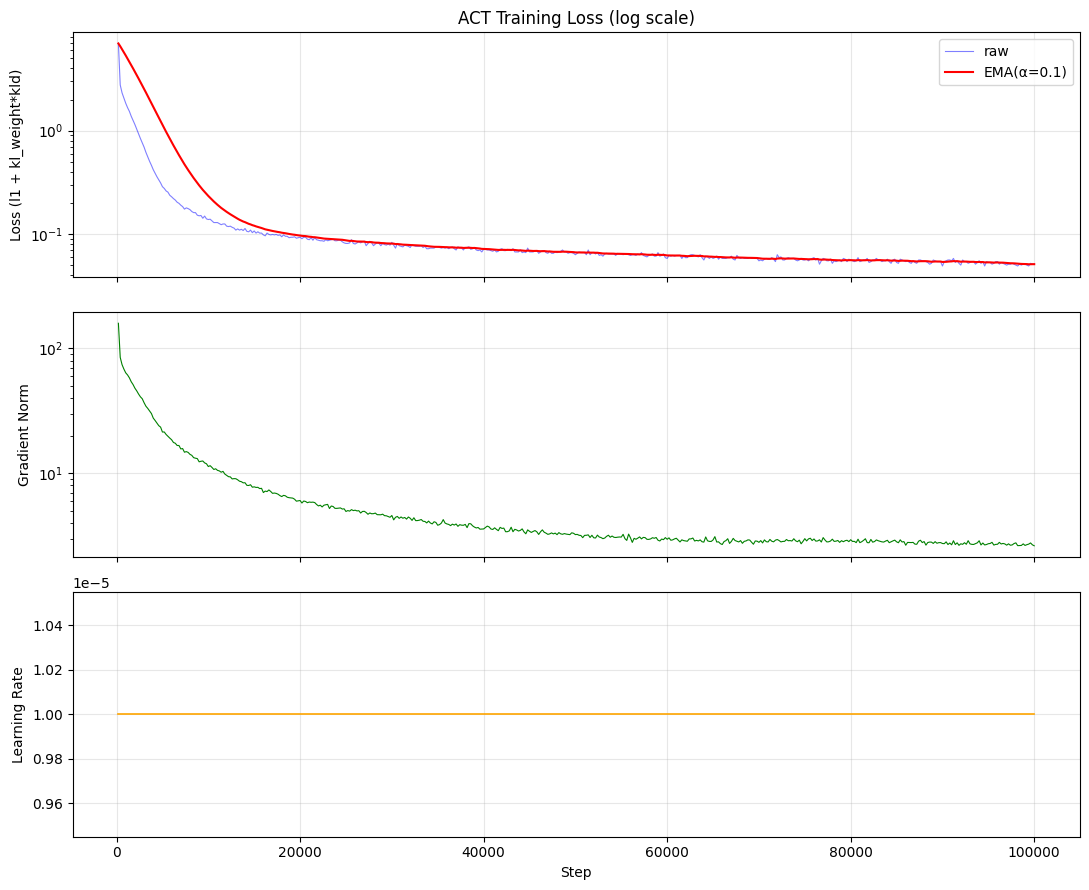


圖已存至: /home/teddyminelab/openarm_isaaclab/outputs/finetune_act_basket/training_curves.png

=== 訓練摘要 ===
  Total steps        : 99,999 / 100,000
  Loss start         : 6.9840
  Loss end           : 0.0510
  Loss min           : 0.0490  @ step 90,000
  Loss last 25 pts mean: 0.0512
  Grdn start / end   : 159.054 / 2.628


In [8]:
import json
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

NB_PATH = Path("/home/teddyminelab/openarm_isaaclab/notebooks/finetune_act_basket.ipynb")
OUT_DIR = Path(TRAIN_OUTPUT_DIR) if "TRAIN_OUTPUT_DIR" in dir() else Path(
    "/home/teddyminelab/openarm_isaaclab/outputs/finetune_act_basket"
)

nb = json.loads(NB_PATH.read_text())
log_chunks = []
for cell in nb["cells"]:
    if cell["cell_type"] != "code":
        continue
    for output in cell.get("outputs", []):
        t = output.get("text", "")
        if isinstance(t, list):
            t = "".join(t)
        if "loss:" in t and "grdn:" in t:
            log_chunks.append(t)
full = "\n".join(log_chunks)

pat = re.compile(
    r"(\d+)/(\d+)\s*\[.*?\].*?loss:([\d.eE+\-]+)\s+grdn:([\d.eE+\-]+)\s+lr:([\d.eE+\-]+)"
)
records = {}
for m in pat.finditer(full):
    step = int(m.group(1))
    records[step] = {
        "step":  step,
        "total": int(m.group(2)),
        "loss":  float(m.group(3)),
        "grdn":  float(m.group(4)),
        "lr":    float(m.group(5)),
    }
if not records:
    raise RuntimeError("找不到訓練 log，請確認 Block 5 已跑且 notebook 已 Ctrl+S 存檔")

records = sorted(records.values(), key=lambda r: r["step"])
steps  = np.array([r["step"]  for r in records])
losses = np.array([r["loss"]  for r in records])
grdns  = np.array([r["grdn"]  for r in records])
lrs    = np.array([r["lr"]    for r in records])
total_steps = records[-1]["total"]

print(f"解析到 {len(records)} 個記錄點，step {steps[0]:,} ~ {steps[-1]:,} / {total_steps:,}")

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

axes[0].plot(steps, losses, "b-", linewidth=0.8, alpha=0.5, label="raw")
if len(losses) > 10:
    alpha_ema = 0.1
    ema = np.zeros_like(losses)
    ema[0] = losses[0]
    for i in range(1, len(losses)):
        ema[i] = alpha_ema * losses[i] + (1 - alpha_ema) * ema[i-1]
    axes[0].plot(steps, ema, "r-", linewidth=1.5, label=f"EMA(α={alpha_ema})")
axes[0].set_ylabel("Loss (l1 + kl_weight*kld)")
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper right")
axes[0].set_title("ACT Training Loss (log scale)")

axes[1].plot(steps, grdns, "g-", linewidth=0.8)
axes[1].set_ylabel("Gradient Norm")
axes[1].set_yscale("log")
axes[1].grid(True, alpha=0.3)

axes[2].plot(steps, lrs, color="orange", linewidth=1.2)
axes[2].set_ylabel("Learning Rate")
axes[2].set_xlabel("Step")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
out_png = OUT_DIR / "training_curves.png"
out_png.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_png, dpi=120, bbox_inches="tight")
plt.show()
print(f"\n圖已存至: {out_png}")

last_n = max(1, len(losses) // 20)
argmin = int(losses.argmin())
print(f"\n=== 訓練摘要 ===")
print(f"  Total steps        : {steps[-1]:,} / {total_steps:,}")
print(f"  Loss start         : {losses[0]:.4f}")
print(f"  Loss end           : {losses[-1]:.4f}")
print(f"  Loss min           : {losses[argmin]:.4f}  @ step {steps[argmin]:,}")
print(f"  Loss last {last_n} pts mean: {losses[-last_n:].mean():.4f}")
print(f"  Grdn start / end   : {grdns[0]:.3f} / {grdns[-1]:.3f}")